In [1]:
import numpy as np
import pandas as pd
from sklearn import datasets

In [2]:
data = datasets.load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target  
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


# Check for Nulls, Shape, Data Types

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

# Descriptive Statistics

Look for weird ranges (outliers, scaling issues)

### what do we mean weird range? and what to do if we find it?

any values in your dataset that look off compared to what you expect. Min or max way outside normal, Negative values where they shouldn’t be, Zeros in features where zero is impossible. prior knowledge matters in DS/ML. Context gives meaning. You can spot if a value makes sense or is physically/impossibly wrong. Without context, a 1000 in “mean radius” could be just numbers, but with domain knowledge, it screams “WRONG”

In [28]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


# Correlation Matrix


See which features are highly correlated, Watch for multicollinearity (might affect models like Logistic Regression). Anything higher than 0.85 goes. i find it easier to just make the correlation be an absolute value between 0 and 1, and this way all the two extremes are the same color and your eyes dont have to jump between two color ways to find sneaky connections between predictors. in this case, the redder, the higher connection.

## What is Multicollinearity?
Multi happens when two or more predictor (independent) variables are highly correlated with each other.
Meaning:
- They’re giving redundant information to the model.
- They're basically saying the same thing in different words.

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

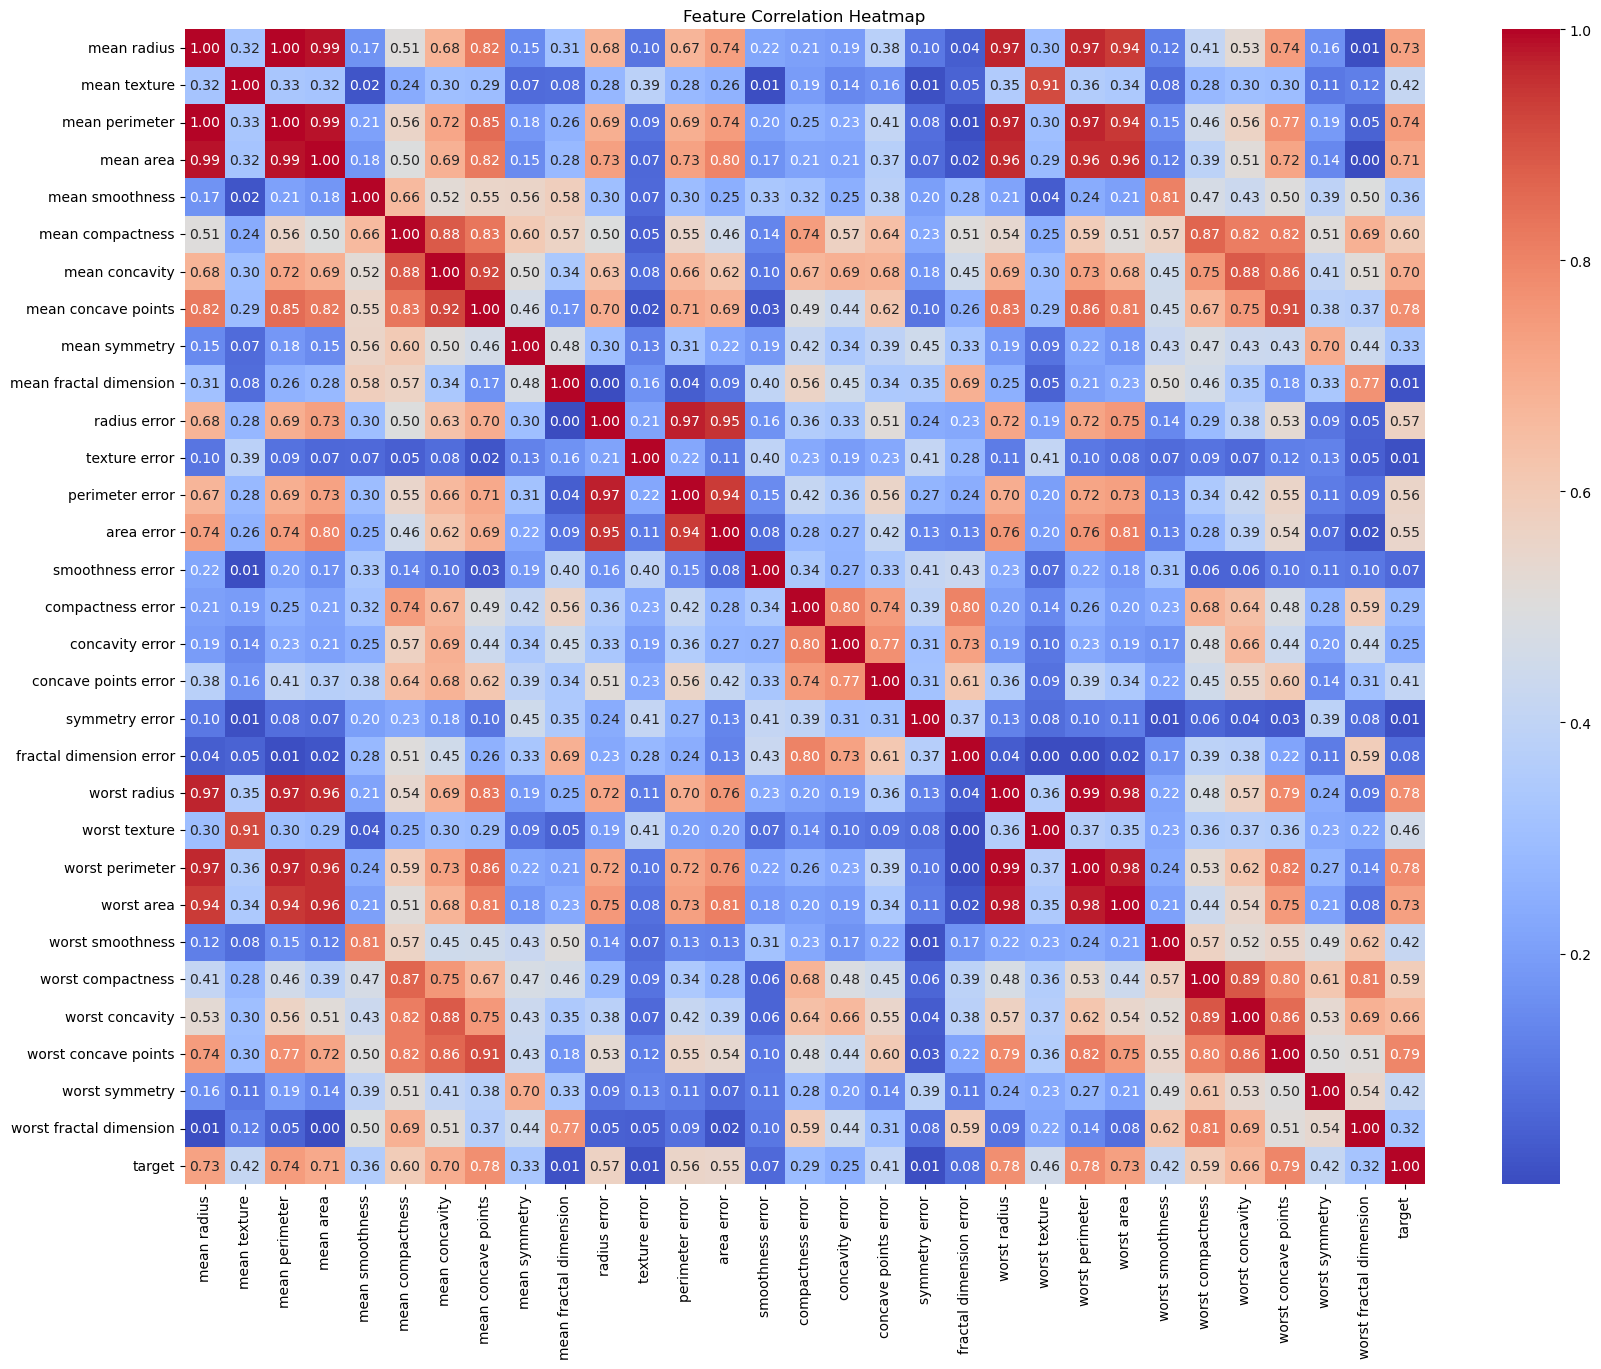

In [6]:
corr_matrix = df.corr().abs()

plt.figure(figsize=(20,15))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Feature Correlation Heatmap');

now that we have itenfied some `heavy relationships`, we either:
- `drop one of the correlated pairs`, meaning we just drop the entire predictor/column.
- or we use dimensionality reduction methods such as `PCA (principal component analysis)`

If lots of features are correlated, PCA can transform them into uncorrelated components. Models like Logistic Regression or Linear Regression love PCA. Random Forest? Doesn’t care much (tree-based models aren’t sensitive)

# BREAKDOWN ELI5

- Each float in `pca.explained_variance_ratio_` represents the variance explained by a `principal component (PC)`.

- The line `pca = PCA(n_components=10)` does nothing by itself. It only becomes meaningful when you call `.fit_transform()` with your dataset. that’s when PCA learns the structure.

- You control how many components to keep using the `n_components` argument.
If you don’t provide it, PCA keeps `all components` (equal to the number of `original features`).

- We don’t just pick a number randomly — the goal is to keep `as few components as possible` while `still capturing 90–95% of the variance`.
These variance values `accumulate`, with the `first PC capturing the most`, and each `following PC explaining less`.

## remember
- PCA is unsupervised, drop the labels ( or seperate it from the table itself and assign it to a variable to use later).

- PCA only works with scaled data, so use one of them to scale the features. we use standardscaler here

- Seperate features and the label for modeling, use `capital X` for `features` and `small y` for the `labels`, remember that the original df still stands untouched and we are creating new dataframes with modified columns.

- we use PCA().fit(X) when we want to first learn components from data (not transform the table yet) and use PCA().fit_transform(X) when we wanna both see and also apply the transformation.

In [7]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

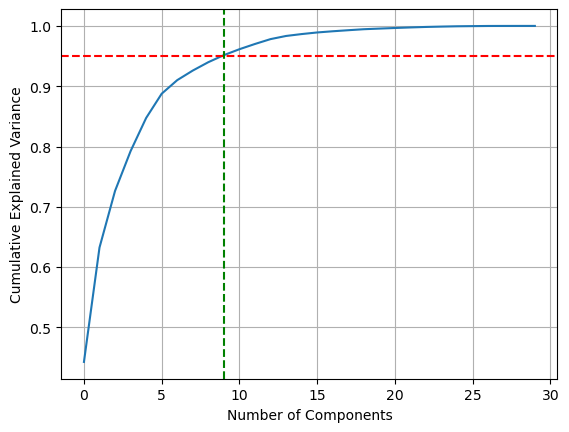

In [8]:
X = df.drop('target', axis=1)
y = df['target']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
pca = PCA().fit(X_scaled)

cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
plt.plot(cumulative_variance)

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.grid(True)
plt.axhline(y=0.95, color='r', linestyle='--')
plt.axvline(x=np.argmax(cumulative_variance >= 0.95), color='g', linestyle='--');

This tells us that `9 PCs are enough to reach 95% of the variance`. so we go with n_components=9. we want to compare the base untouched dataset with all the features with the PCA version having 9 uncorrelated features. 

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

updating X_scaled to be the scaled version of df without the label. we can also check .std(axis=0) and .mean(axis=0) to see if the dataset is actually scaled. in this case (standard scaler) the std should be 1 and the mean should be 0.

In [10]:
X_scaled = scaler.fit_transform(X)
display(X_scaled.std(axis=0), X_scaled.mean(axis=0))

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])

array([-3.16286735e-15, -6.53060890e-15, -7.07889127e-16, -8.79983452e-16,
        6.13217737e-15, -1.12036918e-15, -4.42138027e-16,  9.73249991e-16,
       -1.97167024e-15, -1.45363120e-15, -9.07641468e-16, -8.85349205e-16,
        1.77367396e-15, -8.29155139e-16, -7.54180940e-16, -3.92187747e-16,
        7.91789988e-16, -2.73946068e-16, -3.10823423e-16, -3.36676596e-16,
       -2.33322442e-15,  1.76367415e-15, -1.19802625e-15,  5.04966114e-16,
       -5.21317026e-15, -2.17478837e-15,  6.85645643e-16, -1.41265636e-16,
       -2.28956670e-15,  2.57517109e-15])

## with no PCA usage:

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

model = LogisticRegression()
model.fit(X_train, y_train)
print("Accuracy with untouched features:", model.score(X_test, y_test))

Accuracy with untouched features: 0.9736842105263158


## with 2 PCs usage:

In [12]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
X_pca_df = pd.DataFrame(X_pca)

X_train, X_test, y_train, y_test = train_test_split(X_pca_df, y, test_size=0.2, random_state=42)
model = LogisticRegression()
model.fit(X_train, y_train)
print("Accuracy with the 9 PCs:", model.score(X_test, y_test))


Accuracy with the 9 PCs: 0.9912280701754386


## with 9 PCs usage

In [13]:
pca = PCA(n_components=9)
X_pca = pca.fit_transform(X_scaled)
X_pca_df = pd.DataFrame(X_pca)

X_train, X_test, y_train, y_test = train_test_split(X_pca_df, y, test_size=0.2, random_state=42)
model = LogisticRegression()
model.fit(X_train, y_train)
print("Accuracy with the 9 PCs:", model.score(X_test, y_test))


Accuracy with the 9 PCs: 0.9824561403508771


# how is it that with only 2 PCs, im getting 0.9912 accuracy but with 9 im getting 0.9824?




Variance Explained ≠ Model Accuracy
PCA maximizes variance, not class separability.

- The first 2 PCs may capture variance most relevant for your classification, so your model gets lucky.

- The next 7 PCs add variance that’s less helpful or even noisy, causing slight accuracy drop

- Adding more PCs = more features = model can slightly overfit training noise → test accuracy drops.

# Next step
lets continue with 9 components

In [14]:
pca_df = pd.DataFrame(X_pca)
pca_df.columns = [f'PC{i+1}' for i in range(pca_df.shape[1])]
pca_df['target'] = df['target'].values
pca_df.head()


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,target
0,9.192837,1.948583,-1.123166,-3.633731,1.195110,1.411424,2.159370,-0.398407,-0.157118,0
1,2.387802,-3.768172,-0.529293,-1.118264,-0.621775,0.028656,0.013358,0.240988,-0.711905,0
2,5.733896,-1.075174,-0.551748,-0.912083,0.177086,0.541452,-0.668166,0.097374,0.024066,0
3,7.122953,10.275589,-3.232790,-0.152547,2.960878,3.053422,1.429911,1.059565,-1.405440,0
4,3.935302,-1.948072,1.389767,-2.940639,-0.546747,-1.226495,-0.936213,0.636376,-0.263805,0


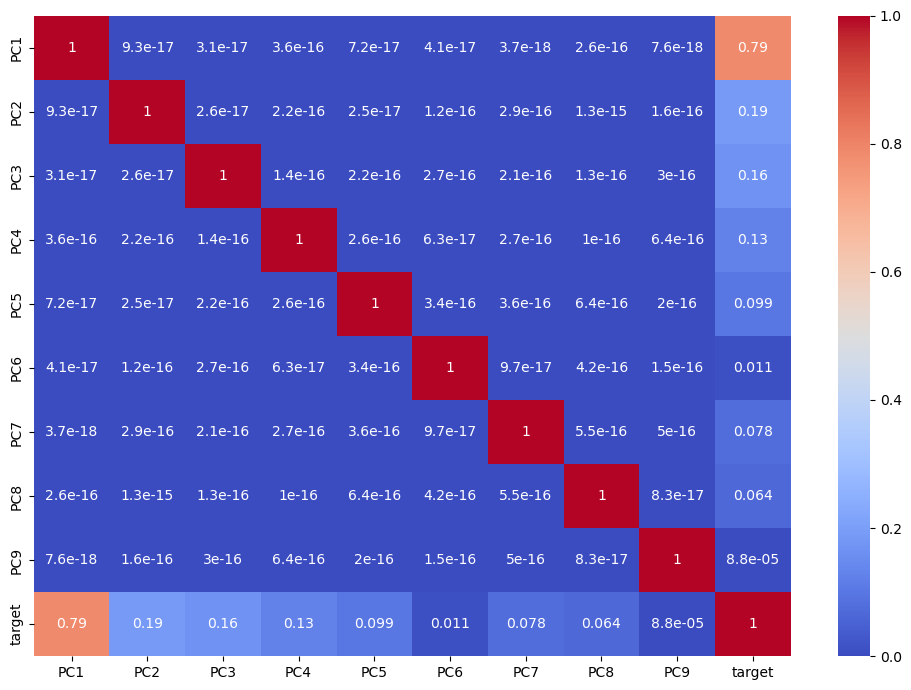

In [15]:
corr = pca_df.corr().abs()
plt.figure(figsize=(10,7))
sns.heatmap(corr, annot=True, cmap='coolwarm')

plt.tight_layout()

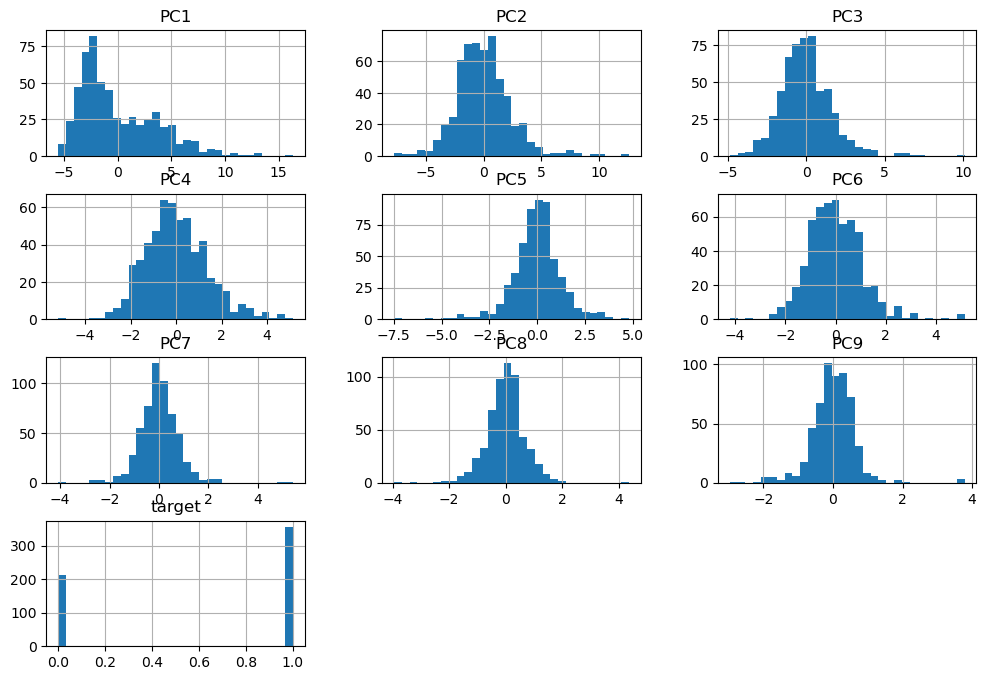

In [16]:
pca_df.hist(bins=30, figsize=(12,8));

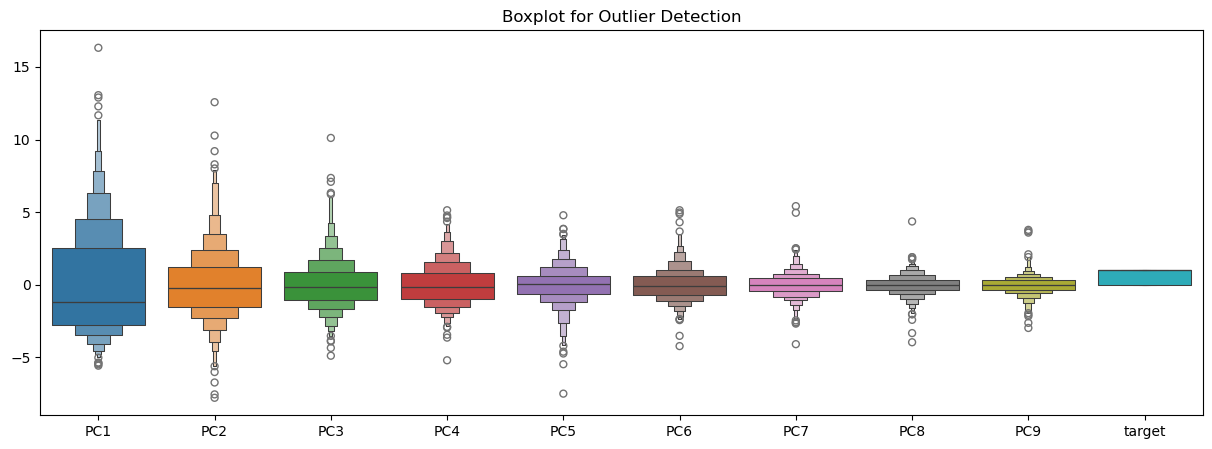

In [ ]:
plt.figure(figsize=(15, 5))
sns.boxenplot(pca_df)


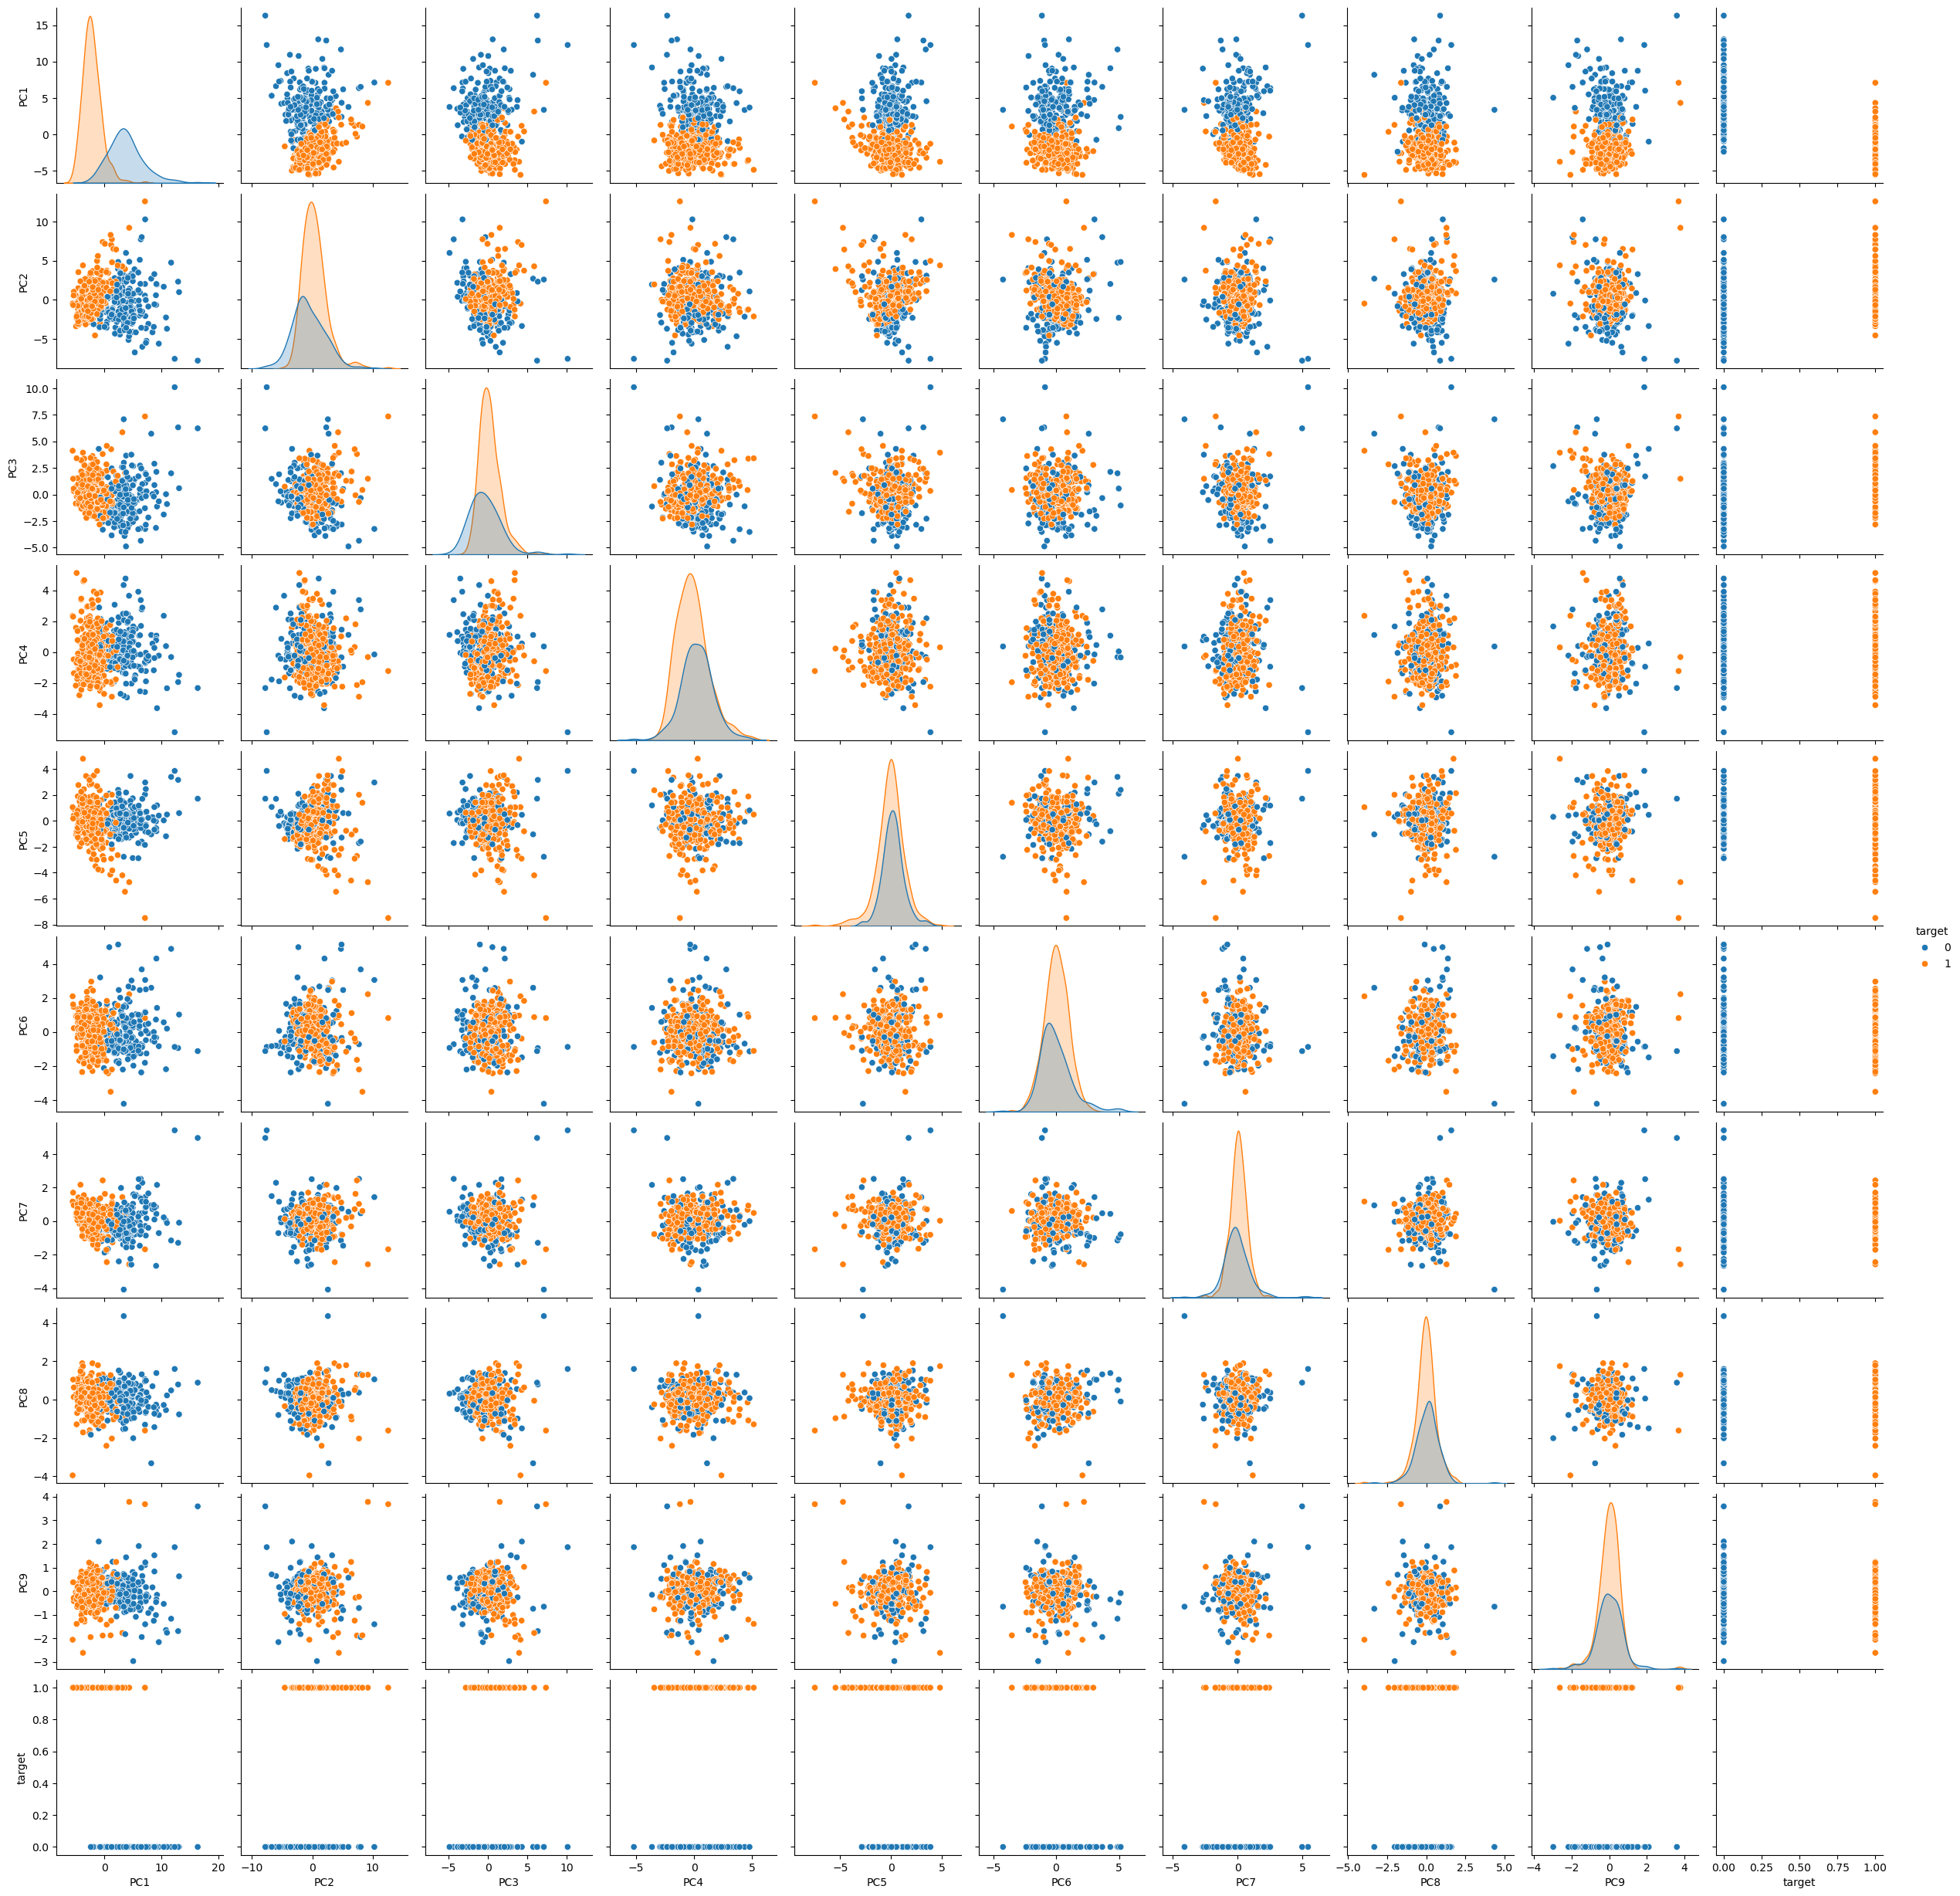

In [18]:
sns.pairplot(pca_df, vars=pca_df.columns, hue='target');